In [1]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow:", tf.__version__)
print("Detected GPUs:", gpus)

if not gpus:
    raise RuntimeError("No GPU detected. Do not start full training.")

print("GPU detection passed.")

TensorFlow: 2.20.0
Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU detection passed.


In [2]:
from pathlib import Path
import hashlib
import sys
import pandas as pd

INPUT_DIR = Path("/kaggle/input")


def find_one(filename):
    matches = list(INPUT_DIR.rglob(filename))

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {filename}, found {len(matches)}: {matches}"
        )

    return matches[0]


# Confirm the audited dataset release.
dataset_dir = find_one("train.txt").parent

expected_hashes = {
    "train.txt": ("52af9a4fdc769396bc5ce530872cf0d51bce""8fd7e25579b333007d4ebee6a6ba" ),
    "test.txt": ("7c92ae0bef49652005e1541a1f2b774e31""3be4431a891cb0aa5539d37ca2a71e"
    ),}

for filename, expected in expected_hashes.items():
    actual = hashlib.sha256(
        (dataset_dir / filename).read_bytes()).hexdigest()
    assert actual == expected, f"Label checksum mismatch: {filename}"

# Restore the existing split; do not generate a new one.
training = pd.read_csv(
    find_one("train.csv"), dtype=str, keep_default_na=False)
validation = pd.read_csv(
    find_one("validation.csv"), dtype=str, keep_default_na=False)

required = {"filename", "label", "patient_id","source", "sha256", "split_group",}

for name, table, count in [
    ("Training", training, 23873),
    ("Validation", validation, 6103),]:
    assert required.issubset(table.columns)
    assert len(table) == count
    assert table["filename"].is_unique
    assert table["sha256"].is_unique
    assert set(table["label"]) == {"negative", "positive"}

    missing = [
        filename for filename in table["filename"]
        if not (dataset_dir / "train" / filename).is_file()]
  
    assert not missing, f"{name}: missing images: {missing[:5]}"

    print(f"{name} images: {len(table)}")

for column in ["filename", "sha256", "split_group"]:
    assert set(training[column]).isdisjoint(validation[column])

# Load shared preprocessing, batch loading, and model architecture.
model_files = list(INPUT_DIR.glob("**/src/covid_xray/model.py"))
assert len(model_files) == 1, (
    f"Expected one model.py, found: {model_files}")

source_dir = model_files[0].parents[1]
sys.path.insert(0, str(source_dir))

from covid_xray.data import make_dataset, LABEL_MAP
from covid_xray.model import build_model

print("Dataset checksums and split checks passed.")
print("Shared batch loader and CNN loaded.")
print("Class mapping:", LABEL_MAP)

Training images: 23873
Validation images: 6103
Dataset checksums and split checks passed.
Shared batch loader and CNN loaded.
Class mapping: {'negative': 0, 'positive': 1}


In [3]:
import time
import numpy as np

tf.keras.utils.set_random_seed(42)

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("GPU is required for this training check.")

train_ds = make_dataset(
    training,
    image_dir=dataset_dir / "train",
    batch_size=32,
    training_mode=True,
    seed=42,
)

val_ds = make_dataset(
    validation,
    image_dir=dataset_dir / "train",
    batch_size=32,
    training_mode=False,
)

# Start with one GPU; two GPUs are not automatically faster
# for this small CNN and Python-based image loading pipeline.
with tf.device("/GPU:0"):
    smoke_model = build_model()

    start = time.perf_counter()

    smoke_history = smoke_model.fit(
        train_ds.take(2),
        validation_data=val_ds.take(1),
        epochs=1,
        verbose=2,
    )

for metric, values in smoke_history.history.items():
    if not np.isfinite(values).all():
        raise RuntimeError(f"Non-finite smoke-run metric: {metric}")

print("Model variable device:", smoke_model.weights[0].handle.device)
print("Elapsed seconds:", round(time.perf_counter() - start, 2))
print("GPU training smoke run passed.")

I0000 00:00:1792340429.184371      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792340429.189580      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1792340442.680875     148 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2/2 - 12s - 6s/step - accuracy: 0.4375 - auc: 0.5290 - loss: 0.9914 - precision: 0.4286 - recall: 1.0000 - val_accuracy: 0.5938 - val_auc: 0.6478 - val_loss: 0.6917 - val_precision: 0.5938 - val_recall: 1.0000
Model variable device: /job:localhost/replica:0/task:0/device:GPU:0
Elapsed seconds: 12.19
GPU training smoke run passed.


In [4]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate weights using only the training subset.
train_labels = (
    training["label"]
    .map(LABEL_MAP)
    .to_numpy(dtype=np.int32)
)

classes = np.array([0, 1], dtype=np.int32)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels,
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

# Apply modest geometric augmentation only during training.
augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomRotation(
            factor=0.02,
            fill_mode="constant",
            fill_value=0.0,
            seed=42,
        ),
        tf.keras.layers.RandomTranslation(
            height_factor=0.03,
            width_factor=0.03,
            fill_mode="constant",
            fill_value=0.0,
            seed=43,
        ),
    ],
    name="training_augmentation",
)

sample_images, sample_labels = next(iter(train_ds))
augmented_images = augmentation(sample_images, training=True)

tf.debugging.assert_equal(
    tf.shape(augmented_images),
    tf.shape(sample_images),
)
tf.debugging.assert_all_finite(
    augmented_images,
    "Non-finite augmented pixels",
)
tf.debugging.assert_greater_equal(augmented_images, 0.0)
tf.debugging.assert_less_equal(augmented_images, 1.0)

print("Class weights:", class_weights)
print("Augmented batch shape:", augmented_images.shape)
print("Augmentation checks passed.")

Class weights: {0: 1.0669020378977476, 1: 0.9409932991722507}
Augmented batch shape: (32, 224, 224, 1)
Augmentation checks passed.


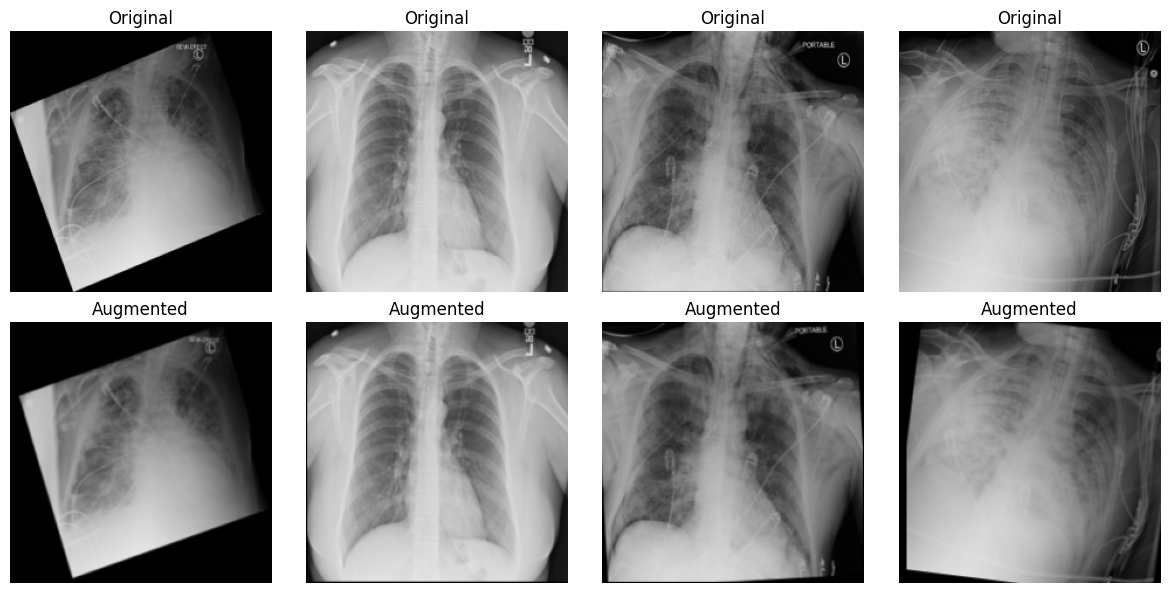

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for column in range(4):
    axes[0, column].imshow(
        sample_images[column, ..., 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[0, column].set_title("Original")

    axes[1, column].imshow(
        augmented_images[column, ..., 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1, column].set_title("Augmented")

for ax in axes.flat:
    ax.axis("off")

fig.tight_layout()
plt.show()
plt.close(fig)

In [6]:
from pathlib import Path
from datetime import datetime, timezone
import json

# Use a separate output directory for each training run.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
run_dir = Path("/kaggle/working/artifacts/runs") / run_id
run_dir.mkdir(parents=True, exist_ok=False)

tf.keras.utils.set_random_seed(42)

# Discard smoke-run weights and build a fresh model.
with tf.device("/GPU:0"):
    model = build_model()

# Augment only training batches; validation remains unchanged.
def augment_batch(images, labels):
    return augmentation(images, training=True), labels


augmented_train_ds = train_ds.map(augment_batch,num_parallel_calls=1,deterministic=True,).prefetch(1)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(filepath=str(run_dir / "best_model.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True, ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-6,),
    tf.keras.callbacks.CSVLogger(
        str(run_dir / "training_history.csv")),
    tf.keras.callbacks.BackupAndRestore(
        backup_dir=str(run_dir / "recovery"),
        delete_checkpoint=False, ),]

run_config = {
    "tensorflow_version": tf.__version__,
    "seed": 42,
    "max_epochs": 30,
    "batch_size": 32,
    "image_shape": [224, 224, 1],
    "training_images": len(training),
    "validation_images": len(validation),
    "class_mapping": LABEL_MAP,
    "class_weights": class_weights,
    "checkpoint_monitor": "val_loss",
    "augmentation": {
        "rotation_factor": 0.02,
        "translation_height": 0.03,
        "translation_width": 0.03, },}

(run_dir / "run_config.json").write_text(
    json.dumps(run_config, indent=2),
    encoding="utf-8",)

print("Fresh model parameters:", model.count_params())
print("Run directory:", run_dir)
print("Training configuration saved. Training has not started.")

Fresh model parameters: 101665
Run directory: /kaggle/working/artifacts/runs/20261018T170010_055087Z
Training configuration saved. Training has not started.


In [7]:
import time

training_start = time.perf_counter()

history = model.fit(
    augmented_train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,)

elapsed = time.perf_counter() - training_start

print("Completed epochs:", len(history.epoch))
print("Training time in minutes:", round(elapsed / 60, 2))
print("Best model:", run_dir / "best_model.keras")

Epoch 1/30
746/747 ━━━━━━━━━━━━━━━━━━━━ 0s 944ms/step - accuracy: 0.7610 - auc: 0.8542 - loss: 0.4504 - precision: 0.8536 - recall: 0.6638

2026-10-18 17:14:18.169351: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 17:14:18.306466: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


747/747 ━━━━━━━━━━━━━━━━━━━━ 862s 1s/step - accuracy: 0.8130 - auc: 0.9034 - loss: 0.3892 - precision: 0.8775 - recall: 0.7533 - val_accuracy: 0.6920 - val_auc: 0.8380 - val_loss: 0.7528 - val_precision: 0.8910 - val_recall: 0.4903 - learning_rate: 0.0010
Epoch 2/30
747/747 ━━━━━━━━━━━━━━━━━━━━ 308s 413ms/step - accuracy: 0.8727 - auc: 0.9430 - loss: 0.3026 - precision: 0.8975 - recall: 0.8585 - val_accuracy: 0.5409 - val_auc: 0.7486 - val_loss: 2.7391 - val_precision: 0.5408 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/30
747/747 ━━━━━━━━━━━━━━━━━━━━ 304s 407ms/step - accuracy: 0.8919 - auc: 0.9554 - loss: 0.2681 - precision: 0.9111 - recall: 0.8827 - val_accuracy: 0.8594 - val_auc: 0.9652 - val_loss: 0.3741 - val_precision: 0.9830 - val_recall: 0.7530 - learning_rate: 0.0010
Epoch 4/30
747/747 ━━━━━━━━━━━━━━━━━━━━ 307s 410ms/step - accuracy: 0.9011 - auc: 0.9623 - loss: 0.2467 - precision: 0.9197 - recall: 0.8918 - val_accuracy: 0.8991 - val_auc: 0.9562 - val_loss: 0.2916 - v

In [8]:
import shutil

required_files = [
    "best_model.keras",
    "training_history.csv",
    "run_config.json",]

for filename in required_files:
    path = run_dir / filename
    if not path.is_file():
        raise FileNotFoundError(path)

backup_path = shutil.make_archive(
    base_name=str(run_dir.parent / f"{run_dir.name}_backup"),
    format="zip",
    root_dir=run_dir.parent,
    base_dir=run_dir.name,)

print("Training backup created:", backup_path)

Training backup created: /kaggle/working/artifacts/runs/20261018T170010_055087Z_backup.zip
